# Group Assignment 1 - Crawler & Regular expression

- **crawl** the real-time content from the “DSAT” website, and use **regular expressions** to extract information.

- Group members: Wang Hongjie, Fang Yuyang, Dong Zeying, Wang Kun, Li Yanyi, Rong Jiaqi

## Step1: environmental preparation

In [5]:
import re
import sqlite3
import time
import gzip
import os
from datetime import datetime

import pandas as pd
from IPython.display import display
from selenium import webdriver
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.common.by import By
from selenium.common.exceptions import UnexpectedAlertPresentException

print("environmental preparation ready")

environmental preparation ready


## Step2: config and database creating

database includes 3 tables:
- `pages`: original page source codes - gzip-compressed
- `stations`: stations' info
- `buses`: buses' info

In [ ]:
BASE_URL = "https://bis.dsat.gov.mo:37812/macauweb/"    # web url
ROUTES = ["25B", "701X", "3", "26A", "17", "29", "25BS", "60"]     # routes of buses
# DB_PATH = "macau_bus.db"        # databease - SQLite 
DB_PATH = "assignment_demo.db"
HEADLESS = False        # True = Headless mode; False = Show browser window

print(f"[INFO] web URL: {BASE_URL}")
print(f"[INFO] bus routes: {ROUTES}")
print(f"[INFO] database file path: {DB_PATH}")

# string of current time
def now_str():
    return datetime.now().strftime("%Y-%m-%d %H:%M:%S")

# create 3 tables in SQLite database
def create_tables(con):
    con.executescript('''
        CREATE TABLE IF NOT EXISTS pages (
            id         INTEGER PRIMARY KEY AUTOINCREMENT,
            crawl_time TEXT NOT NULL,      -- time
            route_name TEXT NOT NULL,      -- route name
            direction  INTEGER NOT NULL,   -- direction - 0 or 1
            html       BLOB,               -- gzip-compressed HTML
            parsed     INTEGER DEFAULT 0   -- 0 = not parsed; 1 = parsed
        );
        CREATE TABLE IF NOT EXISTS stations (
            id            INTEGER PRIMARY KEY AUTOINCREMENT,
            page_id       INTEGER NOT NULL,   -- which page
            seq           INTEGER,            -- order of station in the route, e.g., 0, 1, 2, ...
            station_code  TEXT,               -- station code, e.g., M1/13
            stopcode      TEXT,               -- station number, e.g., 00025001
            station_name  TEXT,               -- station name, e.g., 關閘總站
            lane_name     TEXT                -- lane name, e.g., C 車道
        );
        CREATE TABLE IF NOT EXISTS buses (
            id                   INTEGER PRIMARY KEY AUTOINCREMENT,
            page_id              INTEGER NOT NULL,   -- which page
            segment_seq          INTEGER,            -- vehicle position after which station
            segment_station_code TEXT,               -- station code after which vehicle is located
            bus_plate            TEXT,               -- license plate
            speed_kmh            REAL,               -- speed (km/h)
            position_pct         REAL                -- percentage position on this segment
        );
    ''')
    print("[INFO] data table pages / stations / buses already created or existing")

# init database: open database. create tables if not exist, check compatibility
def init_db(path):
    con = sqlite3.connect(path)
    create_tables(con)
    # compatibility checking
    cols = [c[1] for c in con.execute("PRAGMA table_info(stations)")]
    if cols and "page_id" not in cols:
        con.close()
        os.replace(path, path + ".old")
        print("The new library is being rebuilt... %s" % (path + ".old"))
        con = sqlite3.connect(path)
        create_tables(con)
    return con

con = sqlite3.connect(DB_PATH)
create_tables(con)
print("[INFO] database is ready for use. ✅")


[INFO] web URL: https://bis.dsat.gov.mo:37812/macauweb/
[INFO] bus routes: ['25B', '701X', '3', '26A', '17', '29', '25BS', '60']
[INFO] database file path: assignment_demo.db
[INFO] data table pages / stations / buses already created or existing
[INFO] database is ready for use. ✅


## Step3: crawl dynamic web pages

- The route page loads station and bus information dynamically. 

- **Selenium** opens the page and waits for the station elements to appear 

- before collecting the rendered HTML.

Each available route direction is collected once.

In [17]:
# create browser driver. Selenium will automatically download the matching chromedriver.
def make_driver():
    opts = Options()
    opts.add_argument("--ignore-certificate-errors")  # ignore SSL certificate errors (this web must add)
    opts.add_argument("--window-size=1280,2000")      # window size
    opts.add_argument("--lang=zh-cn")                 # language

    if HEADLESS:
        opts.add_argument("--headless=new")           # headless mode (no browser window)

    driver = webdriver.Chrome(options=opts)
    driver.set_page_load_timeout(60)                       # give up if page load takes more than 60s
    return driver

# construct the URL of a specific route and direction
# direction  --  0 / 1.
def route_url(route, direction):
    return (BASE_URL + "routeLine.html?routeName=%s&direction=%d&language=zh-tw" % (route, direction))

# get the page source of a specific route and direction
# if the direction has no data - return None.
def get_page_source(driver, route, direction):
    try:
        driver.get(route_url(route, direction))
    except UnexpectedAlertPresentException:
        # "no data" alert popped up right after page loading -> skip
        try:
            driver.switch_to.alert.accept()
        except Exception:
            pass
        return None
    deadline = time.time() + 25
    while time.time() < deadline:
        try:
            n = len(driver.find_elements(By.CSS_SELECTOR, "#bus_stations .macau-route-station"))
            if n > 0:
                time.sleep(4)
                return driver.page_source
        except UnexpectedAlertPresentException:
            # no data: the site pops up a "no data" alert.
            # ChromeDriver may have auto-dismissed the alert already,
            # so accept() may fail -> just ignore it.
            try:
                driver.switch_to.alert.accept()
            except Exception:
                pass
            return None     # no data in that direction -> return None
        time.sleep(1)
    return None

# save the page source into the database
def save_page(con, route, direction, html):
    gz = gzip.compress(html.encode("utf-8"))      # compress html source
    con.execute("INSERT INTO pages(crawl_time, route_name, direction, html, parsed) "
                "VALUES(?,?,?,?,0)", (now_str(), route, direction, gz))
    con.commit()

In [18]:
def crawl_once(driver, con, routes):
    for route in routes:
        for direction in (0, 1):
            html = get_page_source(driver, route, direction)
            if html is None:
                print("  %s direction %d has no data, Skip! " % (route, direction))
                continue
            save_page(con, route, direction, html)
            print("  [%s] %s direction %d has been saved (%d)" % (now_str(), route, direction, len(html)))

In [19]:
print("Starting crawler...", flush=True)

driver = make_driver()

try:
    crawl_once(driver, con, ROUTES)
finally:
    driver.quit()

page_count = con.execute("SELECT COUNT(*) FROM pages").fetchone()[0]
print(f"Pages in database: {page_count}")

Starting crawler...
  [2026-10-20 16:45:16] 25B direction 0 has been saved (256045)
  [2026-10-20 16:45:21] 25B direction 1 has been saved (196753)
  [2026-10-20 16:45:26] 701X direction 0 has been saved (136039)
  701X direction 1 has no data, Skip! 
  [2026-10-20 16:45:32] 3 direction 0 has been saved (124561)
  [2026-10-20 16:45:37] 3 direction 1 has been saved (104481)
  [2026-10-20 16:45:43] 26A direction 0 has been saved (237040)
  [2026-10-20 16:45:48] 26A direction 1 has been saved (262450)
  [2026-10-20 16:45:53] 17 direction 0 has been saved (198563)
  17 direction 1 has no data, Skip! 
  [2026-10-20 16:45:59] 29 direction 0 has been saved (174322)
  29 direction 1 has no data, Skip! 
  [2026-10-20 16:46:05] 25BS direction 0 has been saved (71128)
  25BS direction 1 has no data, Skip! 
  [2026-10-20 16:46:12] 60 direction 0 has been saved (136479)
  60 direction 1 has no data, Skip! 
Pages in database: 25


## Step4: extract info using regular expressions

The HTML is divided into station blocks. For each block, regular expressions extract the station information and the buses associated with that route segment.

The extracted records are linked to the original page through page_id.

example:

>```JavaScript
><div id="_0" data-code="M1/13" data-stopcode="00025001" class="macau-route-station">
>    ...
>    <h4 ... station-code="M1/13" station-title="-關閘總站" station-lane-name="C 車道">
>        <span id="M1/13" class="station-code 1">M1/13</span>-關閘總站（C 車道）</h4>
>    ...
>    <div class="busLocDom" style="top: 50%;">          ← 一辆车：位于"本站→下一站"的 50% 处
>        <p class="busPlateL">AB4144</p>
>        <div class="readyStart">27 km/h</div>
>    </div>
></div>
><div id="_1" ...>...</div>   ← the next station
>```


In [20]:
# extract stations and buses from the page source
def parse_route_page(html):
    stations = []
    buses = []

    # 1. match the start tag of each station
    # e.g., <div id="_0" data-code="M1/13" data-stopcode="00025001" class="macau-route-station">
    tag_re = re.compile(
        r'<div id="_(\d+)"'     # id="_0" - the number part
        r' data-code="([^"]+)"'     # data-code="M1/13" - station code
        r' data-stopcode="([^"]+)"'     # data-stopcode="00025001" - station number
        r' class="macau-route-station[^"]*">'       # class
    )
    tags = list(tag_re.finditer(html))      # locate station blocks

    # 2. processing each station
    for i, tag in enumerate(tags):
        seq  = int(tag.group(1))        # station sequence number
        code = tag.group(2)     # station code
        stop = tag.group(3)     # station number

        # content of this station = source code from the start tag of this site to the start tag of the next site
        end   = tags[i + 1].start() if i + 1 < len(tags) else len(html)
        block = html[tag.end():end]

        # 3. extract station and lane name
        # e.g., station-code="M1/13" station-title="-關閘總站" station-lane-name="C 車道"
        m = re.search(r'station-title="([^"]*)" station-lane-name="([^"]*)"', block)
        name = m.group(1).lstrip('-') if m else ''   # station name may have a "-" prefix, remove it
        lane = m.group(2) if m else ''
        stations.append({'seq': seq, 'code': code, 'stopcode': stop,
                         'name': name, 'lane': lane})

        # 4. extract buses at this station
        for bus_tag in re.finditer(r'<div class="busLocDom"', block):
            start = bus_tag.start()
            end2  = block.find('<div class="busLocDom"', start + 1)  # next bus start spot
            if end2 == -1:
                end2 = len(block)
            bus_block = block[start:end2]   # this bus's source code block

            # bus license plate: <p class="busPlateL" style="">AB4144</p>
            plate = re.search(r'<p class="busPlateL"[^>]*>([^<]+)</p>', bus_block)
            if not plate:
                continue
            # bus position: style="top: 50%;"  → 50, represents the bus is at 50% of this segment
            top   = re.search(r'style="top: ([0-9.]+)%', bus_block)
            # bus speed: <div class="readyStart">27 km/h</div>
            speed = re.search(r'<div class="readyStart">\s*([0-9.]+)\s*km/h', bus_block)

            buses.append({
                'page_seq': seq,        # this bus is between "this station" and "next station"
                'station_code': code,       # use "this station" to locate it
                'plate': plate.group(1).strip(),        # bus license plate
                'speed': float(speed.group(1)) if speed else None,      # speed
                'position': float(top.group(1)) if top else None,       # position percentage
            })

    return stations, buses

### Regular expression extraction

1. **Locate station blocks**

   The station start tag provides the station sequence, station code, and stop code. `finditer()` returns both the captured values and their positions in the HTML.

2. **Split the HTML**

   Each station block extends from its start tag to the next station start tag. This keeps bus records associated with the corresponding station segment.

3. **Extract station names**

   The `station-title` and `station-lane-name` attributes provide the station name and lane name.

4. **Extract bus information**

   Each `busLocDom` block represents a bus. Additional expressions extract its plate number, speed, and relative position.

5. **Convert data types**

   Station sequences are converted to integers. Speeds and positions are converted to floats. Missing speeds or positions are stored as None.

In [ ]:
# parse pages that have not been extracted yet, and write the results into stations and buses tables
def parse_pages(con):
    rows = con.execute("SELECT id, html FROM pages WHERE parsed = 0").fetchall()
    for page_id, gz in rows:
        html = gzip.decompress(gz).decode("utf-8")          # unzip back to source code
        stations, buses = parse_route_page(html)            # regular extraction
        print(
            f"Page {page_id}: HTML decompressed → regex extraction → "
            f"{len(stations)} station records, {len(buses)} bus records",
            flush=True
        )
        # wirte into stations table
        con.executemany(
            "INSERT INTO stations(page_id, seq, station_code, stopcode, station_name, lane_name) "
            "VALUES(?,?,?,?,?,?)",
            [(page_id, s['seq'], s['code'], s['stopcode'], s['name'], s['lane'])
             for s in stations])
        # write into buses table
        con.executemany(
            "INSERT INTO buses(page_id, segment_seq, segment_station_code, bus_plate, speed_kmh, position_pct) "
            "VALUES(?,?,?,?,?,?)",
            [(page_id, b['page_seq'], b['station_code'], b['plate'], b['speed'], b['position'])
             for b in buses])
        con.execute("UPDATE pages SET parsed = 1 WHERE id = ?", (page_id,))
        print(f"Page {page_id}: records saved; parsed = 1\n", flush=True)
    return len(rows)

In [23]:
# 1. Extract unparsed pages
with sqlite3.connect(DB_PATH) as result_con:
    pending = result_con.execute(
        "SELECT COUNT(*) FROM pages WHERE parsed = 0"
    ).fetchone()[0]

    print("STEP 4 — REGULAR EXPRESSION EXTRACTION")
    print(f"Pages waiting for extraction: {pending}\n")

    if pending:
        n = parse_pages(result_con)
        print(f"Extraction completed: {n} pages processed.")
    else:
        print("No pending pages. Showing previously saved results.")

    # 2. Summarize the records saved for each page
    summary = pd.read_sql_query(
        """
        SELECT p.id AS page_id,
               p.crawl_time,
               p.route_name,
               p.direction,
               p.parsed,
               (SELECT COUNT(*) FROM stations AS s
                WHERE s.page_id = p.id) AS station_records,
               (SELECT COUNT(*) FROM buses AS b
                WHERE b.page_id = p.id) AS bus_records
        FROM pages AS p
        ORDER BY p.id
        """,
        result_con
    )

    print("\n1. Extraction summary — all saved pages")
    display(summary)

    # 3. Display actual extracted records from the latest parsed page
    last = result_con.execute(
        """
        SELECT id, route_name, direction, crawl_time
        FROM pages
        WHERE parsed = 1
        ORDER BY id DESC
        LIMIT 1
        """
    ).fetchone()

    if last is None:
        print("No parsed pages available. Run Step3 first.")
    else:
        page_id, route, direction, crawl_time = last

        print(
            f"\n2. Example results — page {page_id}, "
            f"route {route}, direction {direction}"
        )
        print(f"Crawl time: {crawl_time}")

        stations_df = pd.read_sql_query(
            """
            SELECT seq, station_code, stopcode,
                   station_name, lane_name
            FROM stations
            WHERE page_id = ?
            ORDER BY seq
            """,
            result_con,
            params=(page_id,)
        )

        buses_df = pd.read_sql_query(
            """
            SELECT segment_seq, segment_station_code,
                   bus_plate, speed_kmh, position_pct
            FROM buses
            WHERE page_id = ?
            ORDER BY segment_seq, id
            """,
            result_con,
            params=(page_id,)
        )

        print(f"\nStation records: {len(stations_df)} — first 10 shown")
        display(stations_df.head(10))

        print(f"\nBus records: {len(buses_df)}")
        if buses_df.empty:
            print("No bus records were extracted from this snapshot.")
        else:
            display(buses_df)

        if stations_df.empty:
            print(
                "Check the saved HTML and station regex: "
                "this page produced no station matches."
            )

STEP 4 — REGULAR EXPRESSION EXTRACTION
Pages waiting for extraction: 0

No pending pages. Showing previously saved results.

1. Extraction summary — all saved pages


,page_id,crawl_time,route_name,direction,parsed,station_records,bus_records
0,1,2026-10-20 16:39:51,25B,0,1,28,14
1,2,2026-10-20 16:39:56,25B,1,1,26,9
2,3,2026-10-20 16:40:01,701X,0,1,22,5
3,4,2026-10-20 16:43:02,25B,0,1,28,14
4,5,2026-10-20 16:43:07,25B,1,1,26,9
5,6,2026-10-20 16:43:12,701X,0,1,22,4
6,7,2026-10-20 16:43:18,3,0,1,16,8
7,8,2026-10-20 16:43:23,3,1,1,15,7
8,9,2026-10-20 16:43:28,26A,0,1,38,8
9,10,2026-10-20 16:43:33,26A,1,1,37,12



2. Example results — page 25, route 60, direction 0
Crawl time: 2026-10-20 16:46:12

Station records: 23 — first 10 shown


,seq,station_code,stopcode,station_name,lane_name
0,0,M239/3,00060001,外港碼頭,A 車道
1,1,M265,00060002,漁人碼頭會展中心,
2,2,M264,00060003,勵庭海景酒店,
3,3,M266,00060004,澳門科學館,
4,4,M257,00060005,新口岸/文化中心,
5,5,M251,00060006,捐血中心,
6,6,M262,00060007,城市日大馬路/波爾圖街,
7,7,M280,00060008,孫逸仙大馬路/觀光塔街,
8,8,M182/1,00060009,旅遊塔/行車隧道,
9,9,M198,00060010,西灣湖景大馬路/媽閣碼頭,



Bus records: 4


,segment_seq,segment_station_code,bus_plate,speed_kmh,position_pct
0,5,M251,AA2594,5.0,50.0
1,10,M183/2,AA2966,2.0,NaN
2,17,M177,AA7645,37.0,50.0
3,20,M259,AA7630,9.0,50.0


# 

# group dataset visualization

## 1. read, associate, and filter data

In [26]:
from pathlib import Path
import zipfile

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# 数据来自组员导出的 ZIP，不使用之前的两个数据库
DATA_DIR = Path("group_export/group_export")
START = pd.Timestamp("2026-10-06")
END = pd.Timestamp("2026-10-13")  # 不包含13号，确保保留12号全天

page_list, bus_list, station_list = [], [], []
keys = ["crawl_time", "route_name", "direction"]

zip_files = sorted(DATA_DIR.glob("*.zip"))
assert zip_files, f"No ZIP files found in: {DATA_DIR.resolve()}"

for path in zip_files:
    with zipfile.ZipFile(path) as z:

        # 直接读取压缩包内的 CSV；字符串类型保留站点编号前导零
        def read_csv(table):
            name = next(
                n for n in z.namelist()
                if n.split("/")[-1] == f"{table}.csv"
            )
            with z.open(name) as f:
                return pd.read_csv(f, dtype=str)

        p = read_csv("pages").rename(columns={"id": "page_id"})
        b = read_csv("buses")
        s = read_csv("stations")

        p["crawl_time"] = pd.to_datetime(p["crawl_time"], errors="coerce")
        p = p[p["crawl_time"].ge(START) & p["crawl_time"].lt(END)]

        # 两种导出格式：有的车辆表需要关联页面，有的已经包含时间和线路
        if "crawl_time" not in b.columns:
            b = b.merge(
                p[["page_id"] + keys],
                on="page_id", how="inner", validate="many_to_one"
            )
        else:
            b["crawl_time"] = pd.to_datetime(b["crawl_time"], errors="coerce")
            b = b.merge(
                p[keys].drop_duplicates(),
                on=keys, how="inner", validate="many_to_one"
            )

        # 站点表也分为逐页记录和无日期的线路参考表两种
        if "page_id" in s.columns:
            s = s.merge(
                p[["page_id", "route_name", "direction"]],
                on="page_id", how="inner", validate="many_to_one"
            )
        else:
            s = s.merge(
                p[["route_name", "direction"]].drop_duplicates(),
                on=["route_name", "direction"],
                how="inner", validate="many_to_one"
            )

        page_list.append(p[keys])
        bus_list.append(b[keys + [
            "segment_seq", "segment_station_code",
            "bus_plate", "speed_kmh", "position_pct"
        ]])
        station_list.append(s[[
            "route_name", "direction", "seq", "station_code",
            "stopcode", "station_name", "lane_name"
        ]])

# 每个压缩包内部完成关联后再合并，避免不同组员的 page_id 相互混淆
pages = pd.concat(page_list, ignore_index=True).drop_duplicates()
buses = pd.concat(bus_list, ignore_index=True).drop_duplicates()
stations = pd.concat(station_list, ignore_index=True).drop_duplicates()

for col in ["speed_kmh", "position_pct"]:
    buses[col] = pd.to_numeric(buses[col], errors="coerce")

assert not pages.empty, "No page snapshots found in the selected period."

# 统一图表风格
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 130,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlepad": 14,
})

BLUE = "#2563EB"
TEAL = "#0D9488"
DAYS = pd.date_range(START, periods=7)

## 2. data overview and collection trends

Page snapshots,Bus observations,Routes,Unique plates,Station codes (reference)
"2,497","15,921",8,247,212


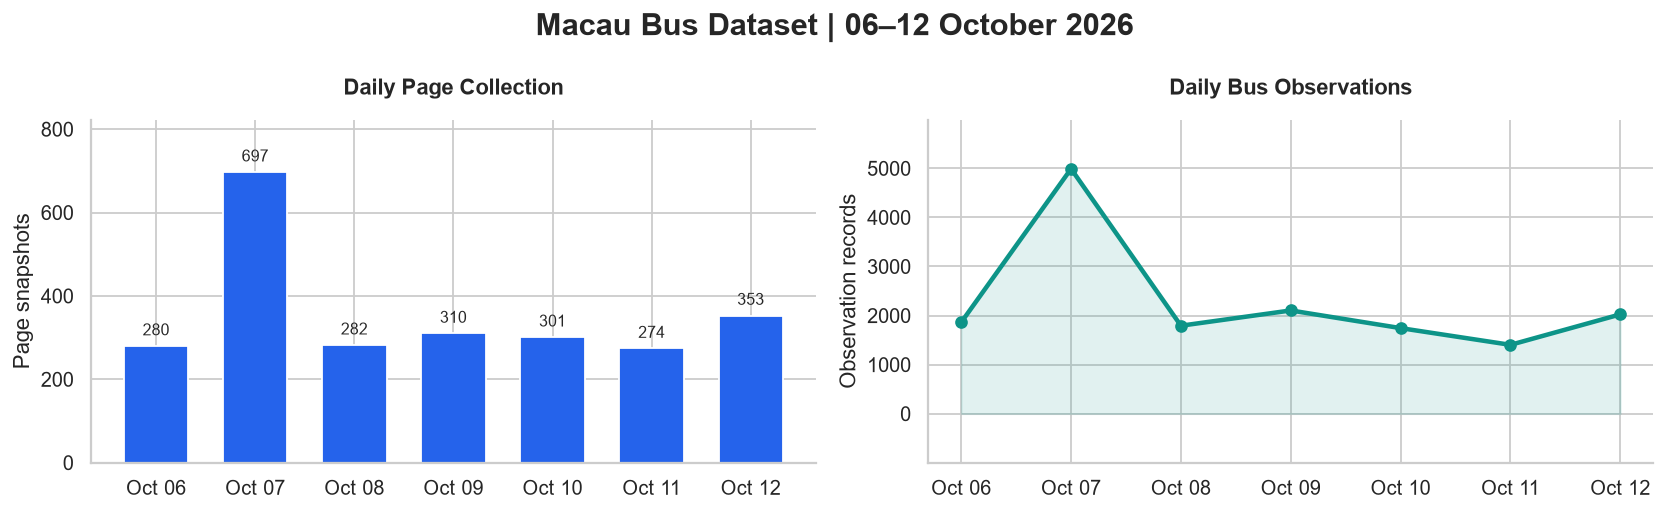

In [27]:
# 概览表；车辆观测记录数不等于不同车辆数
overview = pd.DataFrame({
    "Page snapshots": [len(pages)],
    "Bus observations": [len(buses)],
    "Routes": [pages["route_name"].nunique()],
    "Unique plates": [buses["bus_plate"].nunique()],
    "Station codes (reference)": [stations["station_code"].nunique()],
})

display(
    overview.style
    .format("{:,.0f}")
    .hide(axis="index")
    .set_properties(**{
        "background-color": "#EFF6FF",
        "color": "#1E3A8A",
        "font-size": "16px",
        "padding": "14px",
        "text-align": "center",
    })
)

# 补齐7天，避免缺少数据的日期从横轴消失
daily_pages = pages.groupby(
    pages["crawl_time"].dt.normalize()
).size().reindex(DAYS, fill_value=0)

daily_buses = buses.groupby(
    buses["crawl_time"].dt.normalize()
).size().reindex(DAYS, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
labels = DAYS.strftime("%b %d")

bars = axes[0].bar(labels, daily_pages, color=BLUE, width=0.65)
axes[0].bar_label(bars, padding=4, fontsize=9)
axes[0].set(title="Daily Page Collection", ylabel="Page snapshots")
axes[0].margins(y=0.18)

axes[1].plot(labels, daily_buses, color=TEAL, marker="o", linewidth=2.5)
axes[1].fill_between(labels, daily_buses, color=TEAL, alpha=0.12)
axes[1].set(title="Daily Bus Observations", ylabel="Observation records")
axes[1].margins(y=0.2)

fig.suptitle("Macau Bus Dataset | 06–12 October 2026",
             fontsize=17, fontweight="bold")
fig.tight_layout()
plt.show()

## 3. Visualization

### (1) Average buses per snapshot by route
**created by Wang Kun**

Heatmap of the mean number of buses observed on each route during the afternoon peak. Gray "—" means no snapshot was collected that hour; a 0 means a snapshot was collected but no bus was seen.

In [ ]:
import numpy as np

HOURS = list(range(15, 20))

# buses per snapshot, then averaged by route and hour
buses["hour"] = buses["crawl_time"].dt.hour
per_snap = buses.groupby(["route_name", "crawl_time", "hour"]).size().reset_index(name="n")
mat = per_snap.groupby(["route_name", "hour"])["n"].mean().unstack().reindex(columns=HOURS)

# snapshots per route-hour: tell "not collected" apart from "0 bus"
pages["hour"] = pages["crawl_time"].dt.hour
cnt = pages.groupby(["route_name", "hour"])["crawl_time"].nunique().unstack().reindex(columns=HOURS)

order = mat.mean(axis=1).sort_values(ascending=False).index
mat, cnt = mat.reindex(order), cnt.reindex(order)
mask = cnt.isna() | (cnt.fillna(0) == 0)
M = mat.fillna(0)

fig, ax = plt.subplots(figsize=(8, 5))
cmap = plt.get_cmap("YlOrRd").copy(); cmap.set_bad("#E5E7EB")
ax.imshow(np.where(mask, np.nan, M), cmap=cmap, aspect="auto", vmin=0, vmax=13)
ax.set_xticks(range(len(HOURS)))
ax.set_xticklabels([f"{h}:00" for h in HOURS], rotation=45, ha="right")
ax.set_yticks(range(len(order))); ax.set_yticklabels(list(order))
ax.set_title("Average buses on each route, 15:00–19:00")
ax.set_xlabel("Hour"); ax.set_ylabel("Route")

for i in range(len(order)):
    for j in range(len(HOURS)):
        if mask.iloc[i, j]:
            ax.text(j, i, "—", ha="center", va="center", color="#9CA3AF")
        else:
            v = M.iloc[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center",
                    color="white" if v >= 8 else "#7C2D12")

plt.tight_layout(); plt.show()